# Quantum Privacy Firewall: Final Demo
**Q-Hack India 2026 | Track 02: Quantum Security & Cryptography | Team Fork Around & Find Out**

**The problem:** a quantum program must be transpiled into a physical circuit before it runs on cloud hardware, and that circuit is visible to the provider. Its structure alone can reveal *which algorithm* it implements (algorithmic intent leakage, Buesser & Kurmus, IBM Research).

**This notebook shows, in order:** (1) an attacker identifying a secret workload, (2) QPF generating rewrites and **verifying** each one is equivalent, (3) QPF selecting a rewrite within a hardware budget and the attacker re-attacking, then (4) the measured results over the whole benchmark: 47 generators, 7 algorithm classes, FakeNighthawk backend, 24 and 48 qubits, optimization levels 0-3.

## Setup: load the final dataset and train the attacker

In [1]:
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from qpf import compilation, defenses, verification, paper_circuits as PC, paper_benchmark as PB
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

cfg = PB.load_cfg("full"); BE = cfg["backend"]; FEAT = PB.FEAT          # FEAT = the 10 Table II features
GEN, VARIANT, N, OPT, BUDGET = "qft_swaps", 5, 24, 3, 0.20
LAB = {c: c.replace("_", " ") for c in PC.CLASS_LABELS}

ds = pd.read_csv(ROOT / "artifacts/paper_full/features/dataset.csv")
ds = ds[(ds.status == "OK") & (ds.n_qubits == N) & (ds.opt == OPT)]
truth, sid = PC.GENERATORS[GEN], PC.source_id(GEN, VARIANT)
train = ds[ds.source_id != sid]                                          # victim's source circuit is EXCLUDED
atk = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)).fit(train[FEAT].to_numpy(float), train.intent)
print(f"Attacker trained on {len(train)} compiled circuits ({train.source_id.nunique()} source circuits, {train.intent.nunique()} algorithm classes).")
print(f"Backend: {BE} | features: the 10 normalized Table II features | victim source circuit held out")

Attacker trained on 281 compiled circuits (281 source circuits, 7 algorithm classes).
Backend: FakeNighthawk | features: the 10 normalized Table II features | victim source circuit held out


## Step 1: the victim and the attack
A developer's private 24-qubit workload is transpiled for the backend. The cloud provider sees only the physical circuit.

True class (secret): fourier like
Backend sees: depth=942, two-qubit gates=869, active qubits=24
ATTACK -> predicted 'fourier like' with 100% confidence   *** INTENT LEAKED ***


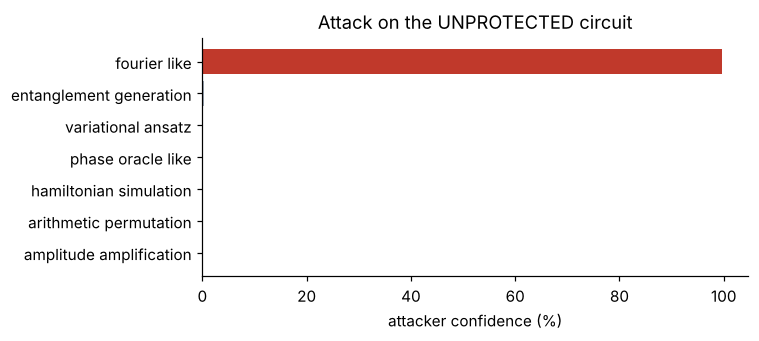

In [2]:
base = PC.make_source(GEN, N, VARIANT)
tc0, _ = compilation.compile_circuit(base, OPT, cfg["transpile_seed"], None, BE)
r0 = PB.physical_row(tc0, BE)
probs = dict(zip(atk.classes_, atk.predict_proba(np.array([[r0[f] for f in FEAT]], float))[0]))
pred = max(probs, key=probs.get); conf0 = probs[pred]
print(f"True class (secret): {LAB[truth]}")
print(f"Backend sees: depth={r0['depth']}, two-qubit gates={r0['n2q']}, active qubits={r0['active']}")
print(f"ATTACK -> predicted '{LAB[pred]}' with {conf0:.0%} confidence   {'*** INTENT LEAKED ***' if pred == truth else ''}")
order = sorted(probs, key=probs.get)
fig, ax = plt.subplots(figsize=(7, 3.2)); ax.barh([LAB[c] for c in order], [probs[c] * 100 for c in order], color=["#c0392b" if c == truth else "#9aa5b1" for c in order])
ax.set_xlabel("attacker confidence (%)"); ax.set_title("Attack on the UNPROTECTED circuit"); plt.tight_layout(); plt.show()

## Step 2: QPF generates rewrites and verifies each one
Seven rewrite strategies (layout, transpiler seed, gate decomposition, commuting-gate reordering, and combinations), three seeds each. **Every rewrite must pass an equivalence check** (MQT QCEC, operator comparison, or a structural-identity check) or it is rejected. Candidates over the 20% overhead budget are excluded.

In [3]:
rows = []; t0 = time.perf_counter()
for si, st in enumerate(cfg["defense"]["strategies"]):
    for k in range(3):
        cseed = 1000 * (si + 1) + k + 1
        cand, layout = defenses.apply_strategy(base, st, cseed, BE)
        v = verification.verify(base, cand, operator_max_qubits=10, qcec_timeout_s=cfg["defense"]["qcec_timeout_s"])
        if v.status != "PASS":
            rows.append(dict(strategy=st, seed=k, verified=f"REJECTED ({v.status})", d_depth=np.nan, d_2q=np.nan, conf=np.nan, ok=False)); continue
        tc, _ = compilation.compile_circuit(cand, OPT, cfg["transpile_seed"] if "seed" not in st.split("+") else int(cseed % 100000) + 1, layout, BE)
        r = PB.physical_row(tc, BE); dd = r["depth"] / r0["depth"] - 1; d2 = r["n2q"] / r0["n2q"] - 1
        p = dict(zip(atk.classes_, atk.predict_proba(np.array([[r[f] for f in FEAT]], float))[0]))
        rows.append(dict(strategy=st, seed=k, verified=f"PASS ({v.method})", d_depth=dd, d_2q=d2, conf=p[pred], pred=max(p, key=p.get), ok=max(dd, d2) <= BUDGET))
T = pd.DataFrame(rows)
show = T.assign(d_depth=T.d_depth.map("{:+.1%}".format), d_2q=T.d_2q.map("{:+.1%}".format), conf=T.conf.map("{:.0%}".format), within_20pct_budget=T.ok.map({True: "yes", False: "NO"}))
display(show[["strategy", "seed", "verified", "d_depth", "d_2q", "conf", "within_20pct_budget"]])
print(f"{len(T)} candidates in {time.perf_counter() - t0:.0f}s: {int(T.verified.str.startswith('PASS').sum())} verified equivalent, {int((~T.verified.str.startswith('PASS')).sum())} rejected")

,strategy,seed,verified,d_depth,d_2q,conf,within_20pct_budget
0,layout,0,PASS (identical_logical_circuit),+25.2%,+34.8%,41%,NO
1,layout,1,PASS (identical_logical_circuit),+34.7%,+30.7%,48%,NO
2,layout,2,PASS (identical_logical_circuit),+20.2%,+24.9%,61%,NO
3,decomp,0,PASS (mqt_qcec),+1.4%,+15.2%,76%,yes
4,decomp,1,PASS (mqt_qcec),-4.5%,+16.2%,63%,yes
5,decomp,2,PASS (mqt_qcec),-7.4%,+11.9%,67%,yes
6,reorder,0,PASS (dag_identity),+0.0%,+0.0%,100%,yes
7,reorder,1,PASS (dag_identity),+0.0%,+0.0%,100%,yes
8,reorder,2,PASS (dag_identity),+0.0%,+0.0%,100%,yes
9,decomp+reorder,0,PASS (mqt_qcec),+14.1%,+19.3%,60%,yes


21 candidates in 5s: 21 verified equivalent, 0 rejected


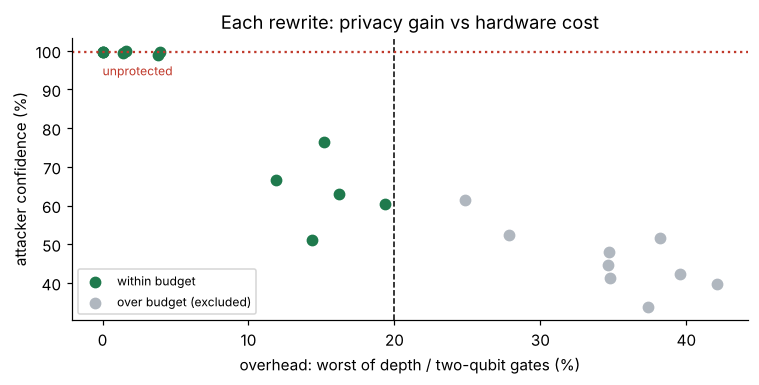

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6)); ov = T[["d_depth", "d_2q"]].max(axis=1) * 100
ax.scatter(ov[T.ok], T.conf[T.ok] * 100, c="#1f7a4d", label="within budget", s=45); ax.scatter(ov[~T.ok], T.conf[~T.ok] * 100, c="#b0b7bf", label="over budget (excluded)", s=45)
ax.axvline(BUDGET * 100, ls="--", c="k", lw=1); ax.axhline(conf0 * 100, ls=":", c="#c0392b"); ax.text(ov.min(), conf0 * 100 - 6, "unprotected", color="#c0392b", fontsize=8)
ax.set_xlabel("overhead: worst of depth / two-qubit gates (%)"); ax.set_ylabel("attacker confidence (%)"); ax.set_title("Each rewrite: privacy gain vs hardware cost"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Step 3: select the best verified rewrite within budget, then attack again
Selection is label-free: lowest attacker confidence in its own original guess, among verified candidates within budget.

Selected: decomp+reorder (seed 2) | depth -9.9% | two-qubit gates +14.4% | equivalence: PASS (mqt_qcec)
ATTACK on protected circuit -> attacker confidence in its original guess: 100% -> 51%
Result: attacker still identifies the algorithm (a reduction, not a cure)


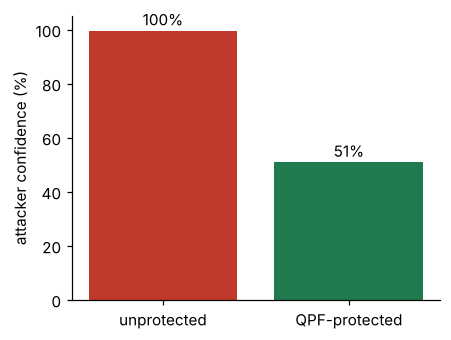

In [5]:
elig = T[T.verified.str.startswith("PASS") & T.ok]
if elig.empty: print("No verified candidate fits the budget: QPF returns the unprotected circuit (it never trades correctness for privacy).")
else:
    b = elig.sort_values("conf").iloc[0]
    print(f"Selected: {b.strategy} (seed {int(b.seed)}) | depth {b.d_depth:+.1%} | two-qubit gates {b.d_2q:+.1%} | equivalence: {b.verified}")
    print(f"ATTACK on protected circuit -> attacker confidence in its original guess: {conf0:.0%} -> {b.conf:.0%}")
    print("Result:", "attacker still identifies the algorithm (a reduction, not a cure)" if b["pred"] == truth else "attacker fooled (this single static attacker)")
    fig, ax = plt.subplots(figsize=(4.2, 3.2)); ax.bar(["unprotected", "QPF-protected"], [conf0 * 100, b.conf * 100], color=["#c0392b", "#1f7a4d"])
    ax.set_ylabel("attacker confidence (%)"); ax.set_ylim(0, 105); [ax.text(i, v + 2, f"{v:.0f}%", ha="center") for i, v in enumerate([conf0 * 100, b.conf * 100])]; plt.tight_layout(); plt.show()

## Step 4: verification across the whole benchmark
The demo above is one circuit. Here is every rewrite in the final defense run: 282 source circuits x 7 strategies.

In [6]:
cand = pd.read_csv(ROOT / "artifacts/paper_full/defense/candidates.csv").drop_duplicates("cid")        # one row per unique candidate circuit
print(f"{len(cand)} unique candidate circuits | all verified equivalent: {bool((cand.verify_status == 'PASS').all())}")
display(cand.groupby(["verify_status", "verify_method"]).size().rename("count").reset_index())

1974 unique candidate circuits | all verified equivalent: True


,verify_status,verify_method,count
0,PASS,dag_identity,564
1,PASS,identical_logical_circuit,564
2,PASS,mqt_qcec,846


## Step 5: how well does the attack work? (full benchmark, 5 repeated source-disjoint splits)
Accuracy of the paper-style attacker when trained on one compiler optimization level (rows) and tested on another (columns). The diagonal is the attacker with matching settings; off-diagonal shows how much the compiler setting changes the leak. Random guessing among 7 classes is about 14%.

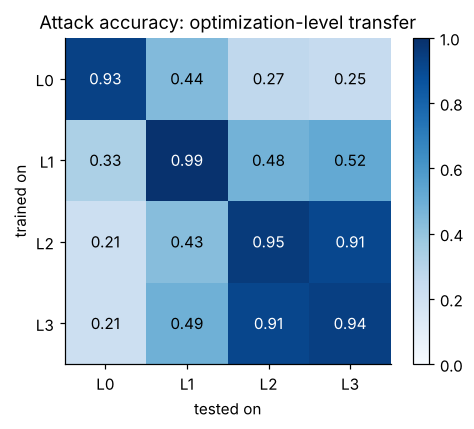

Matching settings: 0.93-0.99 accuracy | mismatched settings: 0.21-0.91 (L2<->L3 transfer is high: 0.91 / 0.91)


In [7]:
pc = pd.read_csv(ROOT / "artifacts/paper_full/results/paper_comparison.csv")
m = pc[(pc.matrix == "optimization_level") & (pc.metric == "accuracy")].copy(); m[["tr", "te"]] = m.train_test.str.split("->", expand=True)
M = m.pivot(index="tr", columns="te", values="ours_mean")
fig, ax = plt.subplots(figsize=(4.8, 4)); im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4), M.columns); ax.set_yticks(range(4), M.index); ax.set_xlabel("tested on"); ax.set_ylabel("trained on"); ax.set_title("Attack accuracy: optimization-level transfer")
[ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", color="white" if M.values[i, j] > .55 else "black") for i in range(4) for j in range(4)]
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
diag = np.diag(M.values); off = M.values[~np.eye(4, dtype=bool)]
print(f"Matching settings: {diag.min():.2f}-{diag.max():.2f} accuracy | mismatched settings: {off.min():.2f}-{off.max():.2f} (L2<->L3 transfer is high: {M.loc['L2','L3']:.2f} / {M.loc['L3','L2']:.2f})")

## Step 6: does the defense reduce the leak? (attacker retrained on protected circuits)
The attacker here **knows the defense exists** and is retrained on protected circuits. Lower macro-F1 means less intent recoverable. **Guided** = QPF's label-free selection; **random** = a random eligible rewrite.

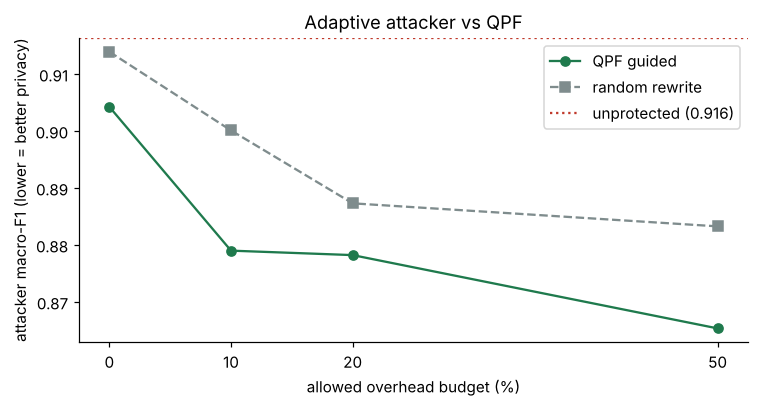

,unprotected,QPF guided,random,drop (guided),95% CI low,95% CI high
0%,0.916,0.904,0.914,0.012,-0.006,0.030
10%,0.916,0.879,0.900,0.037,0.017,0.058
20%,0.916,0.878,0.887,0.038,0.017,0.059
50%,0.916,0.865,0.883,0.051,0.029,0.073


Best: 0.916 -> 0.865 at a 50% budget = 0.051 absolute drop (5.6% relative).


In [8]:
ds_ = pd.read_csv(ROOT / "artifacts/paper_full/results/defense_summary.csv")
ad = ds_[ds_.attacker == "adaptive_pooled"].pivot(index="budget", columns="arm", values="macro_f1_mean")
dl = ds_[ds_.attacker == "DELTA_adaptive_vs_unprotected_abs"].pivot(index="budget", columns="arm", values="macro_f1_mean")
base_f1 = float((ds_[(ds_.attacker == "adaptive_pooled") & (ds_.budget == .5) & (ds_.arm == "guided")].macro_f1_mean.iloc[0]) + dl.loc[.5, "guided"])
x = [b * 100 for b in ad.index]
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.plot(x, ad["guided"], "o-", c="#1f7a4d", label="QPF guided"); ax.plot(x, ad["random"], "s--", c="#7f8c8d", label="random rewrite")
ax.axhline(base_f1, c="#c0392b", ls=":", label=f"unprotected ({base_f1:.3f})"); ax.set_xlabel("allowed overhead budget (%)"); ax.set_ylabel("attacker macro-F1 (lower = better privacy)")
ax.set_xticks(x); ax.set_title("Adaptive attacker vs QPF"); ax.legend(); plt.tight_layout(); plt.show()
ci = ds_[(ds_.attacker == "DELTA_adaptive_vs_unprotected_abs") & (ds_.arm == "guided")].set_index("budget")
out = pd.DataFrame({"unprotected": base_f1, "QPF guided": ad["guided"], "random": ad["random"], "drop (guided)": ci.macro_f1_mean, "95% CI low": ci.ci_lo, "95% CI high": ci.ci_hi}).round(3); out.index = [f"{int(b*100)}%" for b in out.index]
display(out)
print(f"Best: {base_f1:.3f} -> {ad.loc[.5, 'guided']:.3f} at a 50% budget = {dl.loc[.5, 'guided']:.3f} absolute drop ({dl.loc[.5, 'guided'] / base_f1:.1%} relative).")

## Honest reading of the results
- **Intent leakage is real:** the attacker names the algorithm family from the circuit structure alone.
- **The defense helps, modestly:** all rewrites are verified equivalent and within budget, and QPF's guided selection beats random selection, but the drop is about 5 macro-F1 points at a 50% budget. It does **not** provide comprehensive algorithm confidentiality.
- **A metadata-only control** (circuit size and shape, no structural features) scores about 0.94, so part of the signal is basic circuit size.
- **Limits:** generators and feature conventions are our interpretation of the IBM paper; equivalence is verified on the logical rewrite at 24 qubits, not the compiled circuit; everything runs on a simulated backend (FakeNighthawk).
- **Next:** stronger structure-hiding defenses (dummy interactions, phase obfuscation) and real-hardware validation.